Second dataset notebook, E-CAM-S EEG delirium data, Mike Hembree

This is the second dataset for Milestone One and it replaces the Pima diabetes data in the paper (Pima is still in the Wk8 notebook). It comes from the E-CAM-S study at Massachusetts General Hospital (van Sleuwen et al., 2022, Critical Care Medicine), a retrospective study of 373 adult patients who had an EEG as part of routine care for altered mental status between 2015 and 2019. The code and data are on GitHub under an MIT license. Each patient has 1189 features that were already extracted from the EEG (the average, standard deviation, minimum and maximum over the recording of 298 time, spectral power, and coherence measures) plus a clinical delirium severity score called the CAM-S (0 to 7, higher is worse) and a yes or no delirium call from the Confusion Assessment Method.

I set it up like the MIMIC work. Weeks 1 to 3 predict the CAM-S severity score (continuous) and weeks 4 to 6 predict whether the patient was delirious (CAM algorithm positive). The big difference from MIMIC is the shape of the data, 373 patients and 1189 predictors, so there are far more columns than rows. That makes it a really good test for regularization, PCR, and PLSR, and a bad one for anything that fits every column freely. Same idea for validation, repeated five fold cross validation (three repeats for both problems here since the models are heavier), with imputation, scaling, feature screening, and tuning all done inside each training fold.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, roc_auc_score, roc_curve, f1_score, recall_score, precision_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.feature_selection import SequentialFeatureSelector, SelectKBest, f_regression, f_classif
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor


In [2]:
# load the three files from the repo, features, severity score, and the clinical sheet
feat = pd.read_csv('ecams/features_alldata.csv')
cams = pd.to_numeric(pd.read_csv('ecams/CAMS_alldata.csv')['CAMS'])
clin = pd.read_csv('ecams/E_CAM_S_Data.csv')
clin = clin.sort_values('SubjectID-used_for_feature_extraction').reset_index(drop = True)
flag_col = 'CAM algorithm (CAM 1 & 2 , and 3 or 4 SATISFIED - DELIRIUM POSITIVE)'
yc = clin[flag_col].astype(int)
y = cams
print(feat.shape, y.shape, yc.shape)
print('rows lined up by subject id, corr between severity file and clinical CAM-S SF column:', round(np.corrcoef(y, clin['CAM-S SF (0-7)'])[0, 1], 3))
print('delirium positive:', int(yc.sum()), 'of', len(yc), '(' + str(round(yc.mean() * 100, 1)) + '%)')
print('missing values in features:', int(feat.isna().sum().sum()))
print(y.value_counts().sort_index().to_dict())
print('age:', clin['Age '].describe().round(1).to_dict())


(373, 1189) (373,) (373,)
rows lined up by subject id, corr between severity file and clinical CAM-S SF column: 0.962
delirium positive: 254 of 373 (68.1%)
missing values in features: 0
{0: 36, 1: 27, 2: 33, 3: 23, 4: 21, 5: 42, 6: 27, 7: 164}
age: {'count': 373.0, 'mean': 59.6, 'std': 17.5, 'min': 17.5, '25%': 49.0, '50%': 61.0, '75%': 72.0, 'max': 96.0}


The rows line up. The severity file and the clinical sheet agree at a correlation of 0.96 once both are sorted by subject id (not exactly 1, so a few rows differ between the two files, but it's clearly the same patients in the same order). 254 of 373 patients were delirious by the CAM algorithm, which is 68 percent, so unlike MIMIC the positive class is the majority. The severity score is also lopsided, 164 patients sit at the top score of 7.

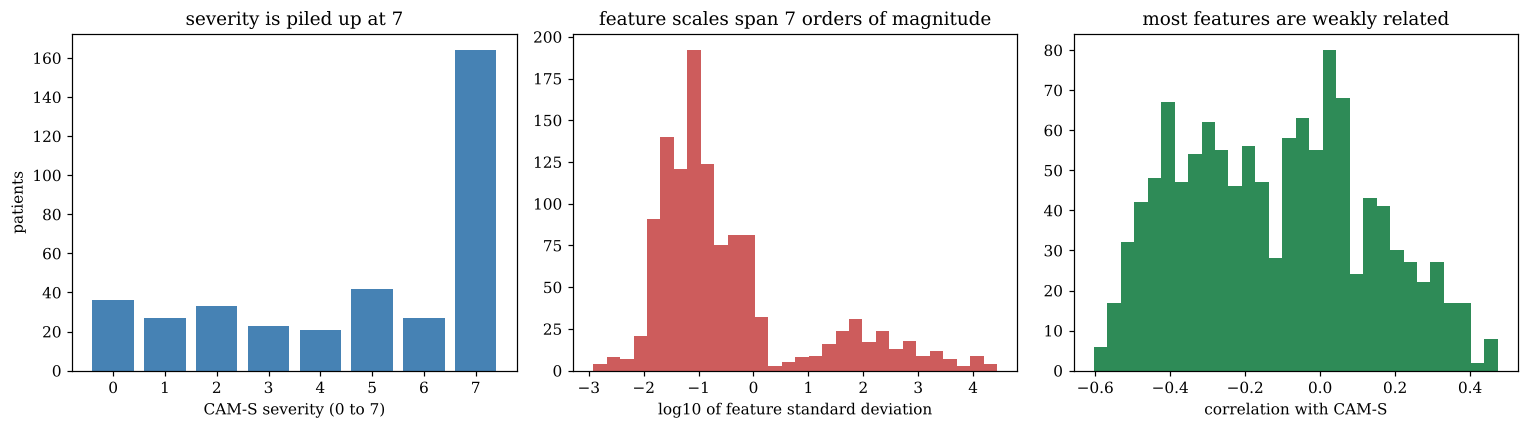

std range: 0.0012 to 27354.8
features with |r| over 0.3 with CAM-S: 409 over 0.5: 51
{"std_time_std_'": 0.6, "std_freq_psd_db_delta_05_2'": 0.6, "std_time_var_'": 0.6, "std_freq_psd_db_delta_02_3'": 0.59, "std_time_sentropy_'": 0.59, "std_freq_psd_db_delta_05_3'": 0.58}


features with another feature at |r| over 0.95: 1058 of 1189


In [3]:
# eda figure, severity distribution, how different the feature scales are, and the strongest correlations
sd = feat.std()
corr_y = feat.corrwith(y).abs().sort_values(ascending = False)
fig, ax = plt.subplots(1, 3, figsize = (14, 4))
ax[0].bar(y.value_counts().sort_index().index, y.value_counts().sort_index().values, color = 'steelblue')
ax[0].set_xlabel('CAM-S severity (0 to 7)')
ax[0].set_ylabel('patients')
ax[0].set_title('severity is piled up at 7')
ax[1].hist(np.log10(sd), bins = 30, color = 'indianred')
ax[1].set_xlabel('log10 of feature standard deviation')
ax[1].set_title('feature scales span 7 orders of magnitude')
ax[2].hist(feat.corrwith(y).dropna(), bins = 30, color = 'seagreen')
ax[2].set_xlabel('correlation with CAM-S')
ax[2].set_title('most features are weakly related')
plt.tight_layout()
plt.savefig('figs/ecams_eda.png', dpi = 200)
plt.show()
print('std range:', round(sd.min(), 4), 'to', round(sd.max(), 1))
print('features with |r| over 0.3 with CAM-S:', int((corr_y > 0.3).sum()), 'over 0.5:', int((corr_y > 0.5).sum()))
print(corr_y.head(6).round(2).to_dict())
cm = feat.corr().abs().values.copy()
np.fill_diagonal(cm, 0)
print('features with another feature at |r| over 0.95:', int((cm.max(axis = 1) > 0.95).sum()), 'of', feat.shape[1])


Three things stand out. Severity piles up at 7, so a model that always predicts the mean gets an rmse of about 2.5 and anything useful has to beat that. The feature scales are all over the place, standard deviations run from about 0.001 to over 27,000, which is why scaling is going to matter a lot here when it didn't on MIMIC. And the features are heavily redundant, 1058 of the 1189 have another feature correlated with them above 0.95. 409 features correlate with severity at more than 0.3 and 51 at more than 0.5, so there's real signal, just spread over lots of copies of the same thing.

In [4]:
# cross validation setup, everything is done inside the pipelines so folds stay clean
X = feat
Xc = feat
cv_reg = RepeatedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42, stratify = yc)

def cv_reg_score(model):
    r = cross_validate(model, X, y, cv = cv_reg, scoring = ('r2', 'neg_root_mean_squared_error'), return_train_score = True, n_jobs = 2)
    return {'train r2': r['train_r2'].mean(), 'cv r2': r['test_r2'].mean(), 'cv rmse': -r['test_neg_root_mean_squared_error'].mean(), 'rmse sd': r['test_neg_root_mean_squared_error'].std()}

print('predicting the mean gives an rmse of about', round(y.std(), 2))


predicting the mean gives an rmse of about 2.54


In [5]:
# week 1, with 1189 columns a degree 2 expansion would be about 700 thousand columns so it can't be done directly
# instead keep the 20 features most related to the target inside each fold and expand those
print(1189 * 1190 // 2 + 1189, 'columns for a full degree 2 expansion')
top20 = lambda: SelectKBest(f_regression, k = 20)
w1 = {
    'linear, all 1189 features': make_pipeline(StandardScaler(), LinearRegression()),
    'week 1 linear on top 20 screened': make_pipeline(StandardScaler(), top20(), LinearRegression()),
    'week 1 interactions only, top 20': make_pipeline(StandardScaler(), top20(), PolynomialFeatures(2, interaction_only = True, include_bias = False), StandardScaler(), LinearRegression()),
    'week 1 degree 2, top 20': make_pipeline(StandardScaler(), top20(), PolynomialFeatures(2, include_bias = False), StandardScaler(), LinearRegression()),
}
rows = []
for name, m in w1.items():
    rows.append({'model': name, **cv_reg_score(m)})
    print(name, round(rows[-1]['cv r2'], 3))
w1_tab = pd.DataFrame(rows)
w1_tab.round(3)


708644 columns for a full degree 2 expansion


linear, all 1189 features -9.951


week 1 linear on top 20 screened 0.351


week 1 interactions only, top 20 -6.377


week 1 degree 2, top 20 -10.743


,model,train r2,cv r2,cv rmse,rmse sd
0,"linear, all 1189 features",1.000,-9.951,6.576,5.179
1,week 1 linear on top 20 screened,0.491,0.351,2.008,0.153
2,"week 1 interactions only, top 20",0.871,-6.377,5.988,3.017
3,"week 1 degree 2, top 20",0.895,-10.743,7.808,3.599


This is the most extreme overfitting I've seen in the whole project. Plain linear regression on all 1189 columns fits the training folds perfectly (train r squared of 1.0) and gets a cv r squared of negative 9.95, an rmse of 6.6 on a score that only goes from 0 to 7. With 298 training rows and 1189 columns it can memorize anything. A full degree 2 expansion would be 708,644 columns so I couldn't do it directly, I screened to the 20 features most related to severity inside each fold and expanded those. Linear on just those 20 is fine (cv r squared 0.35) but adding interactions (negative 6.4) or squares (negative 10.7) blows it up again, same lesson as MIMIC with an even worse ratio of terms to rows.

In [6]:
# weeks 2 and 3 sweeps, number of components for pcr and plsr, number of screened features for selection
sweep = []
for k in [1, 2, 3, 5, 8, 10, 15, 20, 30, 50]:
    sweep.append({'method': 'pcr', 'k': k, **cv_reg_score(make_pipeline(StandardScaler(), PCA(k), LinearRegression()))})
for k in [1, 2, 3, 4, 5, 6, 8, 10]:
    sweep.append({'method': 'plsr', 'k': k, **cv_reg_score(make_pipeline(StandardScaler(), PLSRegression(k)))})
for k in [1, 2, 3, 4, 6, 8]:
    for d in ['forward', 'backward']:
        m = make_pipeline(StandardScaler(), SelectKBest(f_regression, k = 25), SequentialFeatureSelector(LinearRegression(), n_features_to_select = k, direction = d, cv = 3), LinearRegression())
        sweep.append({'method': d + ' selection', 'k': k, **cv_reg_score(m)})
sweep = pd.DataFrame(sweep)
sweep.to_csv('figs/ecams_wk3_sweep.csv', index = False)
sweep.pivot_table(index = 'k', columns = 'method', values = 'cv rmse').round(3)


method,backward selection,forward selection,pcr,plsr
k,,,,
1,2.103,2.098,2.035,1.995
2,2.069,2.071,2.039,1.970
3,2.043,2.044,2.028,1.987
4,2.041,2.042,NaN,2.060
5,NaN,NaN,2.011,2.161
6,2.037,2.040,NaN,2.359
8,2.040,2.049,2.008,2.712
10,NaN,NaN,1.993,2.779
15,NaN,NaN,1.962,NaN


PCR does best around 20 components (rmse 1.95) and gets worse quickly after that, 30 components is 2.08 and 50 is 2.37, because the later components are mostly noise. PLSR is best at only 2 components (1.97) and falls apart at 8 or 10 (2.71 and 2.78), it uses the target to build its components so it overfits faster. Forward and backward selection both level off at 6 variables around 2.04 and agree with each other, though with 1189 columns I had to pre screen to 25 features inside each fold or they would take forever.

In [7]:
# regression comparison table, same footing for every technique
best = sweep.loc[sweep.groupby('method')['cv rmse'].idxmin()].set_index('method')['k'].to_dict()
print(best)
reg_models = {
    'linear (all 1189 features)': w1['linear, all 1189 features'],
    'week 1 interactions only (top 20)': w1['week 1 interactions only, top 20'],
    'week 1 degree 2 (top 20)': w1['week 1 degree 2, top 20'],
    'week 2 ridge': make_pipeline(StandardScaler(), RidgeCV(alphas = np.logspace(0, 5, 30))),
    'week 2 lasso': make_pipeline(StandardScaler(), LassoCV(alphas = np.logspace(-2, 0.5, 25), cv = 3, max_iter = 20000, tol = 1e-3)),
    'week 2 elastic net': make_pipeline(StandardScaler(), ElasticNetCV(alphas = np.logspace(-2, 0.5, 25), l1_ratio = [0.3, 0.7, 0.95], cv = 3, max_iter = 20000, tol = 1e-3)),
    'week 3 forward selection': make_pipeline(StandardScaler(), SelectKBest(f_regression, k = 25), SequentialFeatureSelector(LinearRegression(), n_features_to_select = int(best['forward selection']), direction = 'forward', cv = 3), LinearRegression()),
    'week 3 backward selection': make_pipeline(StandardScaler(), SelectKBest(f_regression, k = 25), SequentialFeatureSelector(LinearRegression(), n_features_to_select = int(best['backward selection']), direction = 'backward', cv = 3), LinearRegression()),
    'week 3 pcr': make_pipeline(StandardScaler(), PCA(int(best['pcr'])), LinearRegression()),
    'week 3 plsr': make_pipeline(StandardScaler(), PLSRegression(int(best['plsr']))),
    'week 6 random forest (extra)': RandomForestRegressor(n_estimators = 300, max_features = 0.1, min_samples_leaf = 3, random_state = 0, n_jobs = 2),
}
rows = []
for name, m in reg_models.items():
    rows.append({'model': name, **cv_reg_score(m)})
    print(name, round(rows[-1]['cv r2'], 3), round(rows[-1]['cv rmse'], 3))
reg_tab = pd.DataFrame(rows)
reg_tab.to_csv('figs/ecams_regression_summary.csv', index = False)
reg_tab.round(3)


{'backward selection': 6, 'forward selection': 6, 'pcr': 20, 'plsr': 2}


linear (all 1189 features) -9.951 6.576


week 1 interactions only (top 20) -6.377 5.988


week 1 degree 2 (top 20) -10.743 7.808


week 2 ridge 0.358 1.998


...

week 3 backward selection 0.332 2.037


week 3 pcr 0.39 1.952


week 3 plsr 0.381 1.97


week 6 random forest (extra) 0.456 1.844


,model,train r2,cv r2,cv rmse,rmse sd
0,linear (all 1189 features),1.000,-9.951,6.576,5.179
1,week 1 interactions only (top 20),0.871,-6.377,5.988,3.017
2,week 1 degree 2 (top 20),0.895,-10.743,7.808,3.599
3,week 2 ridge,0.587,0.358,1.998,0.188
4,week 2 lasso,0.574,0.319,2.053,0.267
5,week 2 elastic net,0.585,0.352,2.007,0.211
6,week 3 forward selection,0.442,0.331,2.040,0.173
7,week 3 backward selection,0.444,0.332,2.037,0.167
8,week 3 pcr,0.488,0.390,1.952,0.121
9,week 3 plsr,0.485,0.381,1.970,0.111


Every technique that controls variance beats plain linear regression by a mile. PCR with 20 components has the best cv r squared of the linear methods (0.39), then PLSR (0.38), ridge (0.36), elastic net (0.35), forward and backward selection (0.33) and lasso (0.32). The random forest I added as an extra is the best of anything at 0.46 and an rmse of 1.84 against 2.54 for guessing the mean. The 0.39 for PCR and 0.38 for PLSR come from picking the number of components off the same cv curve so they're a bit optimistic, ridge and lasso chose their own penalty inside each fold so those are fairer.

In [8]:
# holdout check plus what lasso keeps and how many pcr components it takes
def hold(name, model):
    model.fit(X_train, y_train)
    p = np.ravel(model.predict(X_test))
    return {'model': name, 'test r2': r2_score(y_test, p), 'test rmse': mean_squared_error(y_test, p) ** 0.5}

print(pd.DataFrame([hold(k, v) for k, v in reg_models.items()]).round(3))
lasso_fit = reg_models['week 2 lasso'].fit(X, y)
nz = np.flatnonzero(lasso_fit[-1].coef_)
print('lasso alpha:', round(lasso_fit[-1].alpha_, 4), 'nonzero coefficients:', len(nz), 'of', X.shape[1])
print(pd.Series(lasso_fit[-1].coef_[nz], index = X.columns[nz]).sort_values(key = abs, ascending = False).head(6).round(3).to_dict())
ridge_fit = reg_models['week 2 ridge'].fit(X, y)
print('ridge alpha:', round(ridge_fit[-1].alpha_, 1))
pca = make_pipeline(StandardScaler(), PCA()).fit(X)
print('variance explained by first 1, 5, 10, 20 components:', pca[-1].explained_variance_ratio_.cumsum()[[0, 4, 9, 19]].round(3).tolist())


                                model  test r2  test rmse
0          linear (all 1189 features)   -3.216      5.431
1   week 1 interactions only (top 20)   -2.403      4.879
2            week 1 degree 2 (top 20)   -2.603      5.021
3                        week 2 ridge    0.377      2.088
4                        week 2 lasso    0.388      2.068
5                  week 2 elastic net    0.406      2.038
6            week 3 forward selection    0.299      2.214
7           week 3 backward selection    0.287      2.233
8                          week 3 pcr    0.491      1.887
9                         week 3 plsr    0.402      2.045
10       week 6 random forest (extra)    0.466      1.933


lasso alpha: 0.1101 nonzero coefficients: 44 of 1189
{"std_time_std_'": -0.422, "avg_freq_psd_db_beta_21_29'": -0.235, "max_freq_mean_cohere_delta_02_3'": -0.231, "avg_ratio_sum_cohere_thetaValphalow'": 0.218, "avg_freq_sum_cohere_beta_21_29'": 0.202, "std_ratio_mean_cohere_deltathetamidValphabetamid'": -0.19}
ridge alpha: 1887.4


variance explained by first 1, 5, 10, 20 components: [0.196, 0.547, 0.687, 0.796]


The holdout is 75 patients and it says about the same thing, linear regression is at negative 3.2 and ridge, lasso, and elastic net are around 0.38 to 0.41, with PCR highest at 0.49. Ridge picked a huge penalty (alpha of about 1900) which means it wants to shrink everything hard. Lasso kept 44 of the 1189 features and the biggest one was the standard deviation of the EEG signal over time. Lasso still did worse than ridge, which makes sense with so many near copies of the same feature, lasso tends to grab one from each group and drop the rest, while ridge spreads the weight across them. Only 5 principal components explain 55 percent of the variance and 20 explain 80 percent, so there really is a low dimensional structure which is why PCR works well.

In [9]:
# classification, weeks 4 to 6, tuning is nested inside each outer fold
rf_grid = {'max_depth': [3, 5, None], 'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.1]}
clf_models = {
    'week 4 logistic, unscaled': make_pipeline(LogisticRegression(C = 0.001, max_iter = 5000)),
    'week 4 logistic, scaled': make_pipeline(StandardScaler(), LogisticRegression(C = 0.001, max_iter = 5000)),
    'week 4 logistic, cv regularized': make_pipeline(StandardScaler(), LogisticRegressionCV(Cs = np.logspace(-5, -1, 9), cv = 5, scoring = 'roc_auc', max_iter = 5000)),
    'week 4 logistic, cv balanced': make_pipeline(StandardScaler(), LogisticRegressionCV(Cs = np.logspace(-5, -1, 9), cv = 5, scoring = 'roc_auc', max_iter = 5000, class_weight = 'balanced')),
    'week 5 linear svm, tuned': GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel = 'linear', class_weight = 'balanced')), {'svc__C': [0.00001, 0.0001, 0.001, 0.01]}, scoring = 'roc_auc', cv = 5),
    'week 5 rbf svm, tuned': GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel = 'rbf', class_weight = 'balanced')), {'svc__C': [1, 10, 100], 'svc__gamma': [0.00003, 0.0001, 0.0003, 0.001]}, scoring = 'roc_auc', cv = 5),
    'week 6 decision tree, tuned': GridSearchCV(DecisionTreeClassifier(class_weight = 'balanced', random_state = 0), {'max_depth': [2, 3, 4, 5, 6], 'min_samples_leaf': [1, 3, 5, 10]}, scoring = 'roc_auc', cv = 5),
    'week 6 random forest, default': RandomForestClassifier(n_estimators = 300, random_state = 0),
    'week 6 random forest, tuned': GridSearchCV(RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0), rf_grid, scoring = 'roc_auc', cv = 5),
}
scoring = ('roc_auc', 'recall', 'precision', 'f1', 'accuracy')
rows = []
for name, m in clf_models.items():
    r = cross_validate(m, Xc, yc, cv = cv_clf, scoring = scoring, n_jobs = 2)
    rows.append({'model': name, 'auc': r['test_roc_auc'].mean(), 'auc sd': r['test_roc_auc'].std(), 'recall': r['test_recall'].mean(), 'precision': r['test_precision'].mean(), 'f1': r['test_f1'].mean(), 'accuracy': r['test_accuracy'].mean()})
    print(name, round(rows[-1]['auc'], 3))
clf_tab = pd.DataFrame(rows)
clf_tab.to_csv('figs/ecams_classification_summary.csv', index = False)
clf_tab.round(3)


week 4 logistic, unscaled 0.733


week 4 logistic, scaled 0.877


week 4 logistic, cv regularized 0.872


week 4 logistic, cv balanced 0.874


week 5 linear svm, tuned 0.87


week 5 rbf svm, tuned 0.875


week 6 decision tree, tuned 0.773


week 6 random forest, default 0.898


week 6 random forest, tuned 0.898


,model,auc,auc sd,recall,precision,f1,accuracy
0,"week 4 logistic, unscaled",0.733,0.040,0.795,0.791,0.793,0.718
1,"week 4 logistic, scaled",0.877,0.037,0.899,0.840,0.868,0.814
2,"week 4 logistic, cv regularized",0.872,0.037,0.916,0.809,0.855,0.786
3,"week 4 logistic, cv balanced",0.874,0.036,0.785,0.902,0.838,0.794
4,"week 5 linear svm, tuned",0.870,0.039,0.730,0.915,0.810,0.769
5,"week 5 rbf svm, tuned",0.875,0.039,0.795,0.897,0.841,0.797
6,"week 6 decision tree, tuned",0.773,0.057,0.734,0.873,0.794,0.743
7,"week 6 random forest, default",0.898,0.024,0.882,0.858,0.869,0.819
8,"week 6 random forest, tuned",0.898,0.023,0.814,0.902,0.854,0.811


Scaling is the story here. Logistic regression on the raw features gets an auc of 0.733 and the same model with standardized features gets 0.877. The raw version is held back because features with huge variances either dominate or get crushed by the penalty. This is the opposite of MIMIC where it made no difference. After scaling everything lands in a tight band, logistic regression 0.877, the cv tuned versions 0.872 to 0.874, linear svm 0.870, rbf svm 0.875, so the kernel doesn't buy anything, and the tuned single tree is way behind at 0.773. The random forest is on top at 0.898 and is also the steadiest, fold to fold standard deviation of 0.023 against about 0.04 for the others. Balanced class weights lowered recall here (0.78 against 0.90) which makes sense since delirium is the majority class this time, so recall is easy and precision is the harder number.

In [10]:
# tree depth sweep, training auc against cv auc
rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    m = DecisionTreeClassifier(max_depth = d, class_weight = 'balanced', random_state = 0)
    r = cross_validate(m, Xc, yc, cv = cv_clf, scoring = 'roc_auc', return_train_score = True, n_jobs = 2)
    rows.append({'depth': 'none' if d is None else d, 'train auc': r['train_score'].mean(), 'cv auc': r['test_score'].mean()})
depth_tab = pd.DataFrame(rows)
depth_tab.to_csv('figs/ecams_tree_depth.csv', index = False)
depth_tab.round(3)


,depth,train auc,cv auc
0,1,0.812,0.791
1,2,0.866,0.777
2,3,0.907,0.772
3,4,0.932,0.744
4,5,0.953,0.752
5,6,0.964,0.734
6,8,0.978,0.725
7,10,0.986,0.715
8,none,1.000,0.713


Same picture as the MIMIC trees. Training auc climbs from 0.81 at depth 1 to 1.00 with no limit, while cv auc is highest at depth 1 (0.79) and slides down to 0.71 for an unrestricted tree. With this many redundant features, a deeper tree just finds more ways to split on noise.

In [11]:
# tuned settings on the full data, forest importance and the logistic penalty that got picked
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold

gs = GridSearchCV(RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0), rf_grid, scoring = 'roc_auc', cv = 5, n_jobs = 2).fit(Xc, yc)
print('rf best:', gs.best_params_, round(gs.best_score_, 3))
imp = pd.Series(gs.best_estimator_.feature_importances_, index = Xc.columns).sort_values(ascending = False)
print(imp.head(8).round(3).to_dict())
perm = []
for tr, te in StratifiedKFold(5, shuffle = True, random_state = 3).split(Xc, yc):
    f = RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0, **gs.best_params_).fit(Xc.iloc[tr], yc.iloc[tr])
    p = permutation_importance(f, Xc.iloc[te], yc.iloc[te], scoring = 'roc_auc', n_repeats = 5, random_state = 0)
    perm.append(p.importances_mean)
perm = pd.Series(np.mean(perm, axis = 0), index = Xc.columns).sort_values(ascending = False)
print(perm.head(8).round(3).to_dict())
lr = clf_models['week 4 logistic, cv regularized'].fit(Xc, yc)
print('logistic cv C:', lr[-1].C_)
svm_rbf = clf_models['week 5 rbf svm, tuned'].fit(Xc, yc)
print('rbf best:', svm_rbf.best_params_, round(svm_rbf.best_score_, 3))


rf best: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3} 0.876
{"std_freq_sum_cohere_delta_02_3'": 0.019, "std_freq_psd_db_delta_05_2'": 0.018, "std_time_var_'": 0.015, "std_freq_mean_cohere_delta_05_3'": 0.015, "std_freq_psd_db_delta_02_3'": 0.015, "std_freq_mean_cohere_delta_05_2'": 0.014, "std_freq_sum_cohere_delta_05_3'": 0.013, "std_time_sentropy_'": 0.012}


{"std_time_std_'": 0.001, "avg_freq_psd_db_alpha_8_13'": 0.001, "std_time_sentropy_'": 0.001, "avg_freq_psd_db_alpha_8_11'": 0.001, "std_freq_psd_rel_beta_11_20'": 0.001, "min_ratio_mean_cohere_thetaVthetaalpha'": 0.001, "std_ratio_mean_cohere_deltaValphabeta'": 0.001, "max_freq_psd_db_alpha_8_12'": 0.001}


logistic cv C: [0.00316228]


rbf best: {'svc__C': 1, 'svc__gamma': 0.0003} 0.87


The forest chose unlimited depth with square root features and at least 3 patients per leaf, with a cv auc of 0.876 on the full data. The importance numbers are tiny and spread out, the top impurity importance is only 0.019 and the permutation importances are about 0.001 each, because dozens of near copies of the same EEG feature share the credit and shuffling just one of them barely hurts. Most of the top ones are standard deviations of the delta band power or coherence over time, which fits the paper's point that variability matters, not just the average. Logistic regression's cv picked a very small C (0.003) so it likes very strong shrinkage as well.

In [12]:
# single stratified holdout split for comparison with the weeks 4 to 6 notebooks
def hold_clf(name, model):
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    s = model.decision_function(Xc_test) if hasattr(model, 'decision_function') else model.predict_proba(Xc_test)[:, 1]
    return {'model': name, 'accuracy': accuracy_score(yc_test, pred), 'recall': recall_score(yc_test, pred), 'f1': f1_score(yc_test, pred), 'auc': roc_auc_score(yc_test, s)}

pick = ['week 4 logistic, scaled', 'week 4 logistic, cv balanced', 'week 5 rbf svm, tuned', 'week 6 decision tree, tuned', 'week 6 random forest, tuned']
print(pd.DataFrame([hold_clf(k, clf_models[k]) for k in pick]).round(3))
print('test rows:', len(yc_test), 'positives:', int(yc_test.sum()))


                          model  accuracy  recall     f1    auc
0       week 4 logistic, scaled     0.813   0.882  0.865  0.892
1  week 4 logistic, cv balanced     0.760   0.725  0.804  0.898
2         week 5 rbf svm, tuned     0.813   0.804  0.854  0.910
3   week 6 decision tree, tuned     0.693   0.667  0.747  0.775
4   week 6 random forest, tuned     0.827   0.804  0.863  0.873
test rows: 75 positives: 51


On the holdout of 75 patients (51 delirious) the aucs range from 0.775 for the tree to 0.910 for the rbf svm, with the forest at 0.873 and logistic regression at 0.892 and 0.898. That's a different ordering than repeated cross validation, which had the forest on top, so I'm going with the cv numbers. With 24 negative patients in the test set a handful of patients can move these around.